# The Third Model
Trying to implement U-Net with tensorflow implementation.<br>
Building the U-Net Architecture

### Importing the dependencies

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Activation, ReLU
from tensorflow.keras.layers import BatchNormalization, Conv2DTranspose, Concatenate
from tensorflow.keras.models import Model, Sequential

### Building the Convolution Block
The convolution operation block is used to perform the primary operation of taking the entered input parameters and processing a double layer of convolution operations. In this function, we have two arguments, namely the input for the convolution layer and the number of filters, which is by default 64. <br>
These convolutional layers are followed by the Batch Normalization layer.

In [ ]:
def convolution_operation(entered_input, filters=64):
    # Taking first input and implementing the first conv block
    conv1 = Conv2D(filters, kernel_size = (3,3), padding = "same")(entered_input)
    batch_norm1 = BatchNormalization()(conv1)
    act1 = ReLU()(batch_norm1)

    # Taking first input and implementing the second conv block
    conv2 = Conv2D(filters, kernel_size = (3,3), padding = "same")(act1)
    batch_norm2 = BatchNormalization()(conv2)
    act2 = ReLU()(batch_norm2)

    return act2

### Constructing the encoder and decoder blocks
The encoder architecture will use consecutive inputs starting from the first layer all the way to the bottom. The encoder function as we have defined will have the convolutional block, i.e., two convolutional layers followed by their respective batch normalization and ReLU layers. Once we pass them through the convolution blocks, we will quickly downsample these elements.
<br>
The decoder block will include three arguments, namely the receiving inputs, the input of the skip connection, and the number of filters in the particular building block. We will upsample the entered input with the help of the Conv2DTranspose layers in our model. We will then concatenate both the receiving input and the newly upsampled layers to receive the final value of the skip connections.

In [ ]:
def encoder(entered_input, filters=64):
    # Collect the start and end of each sub-block for normal pass and skip connections
    enc1 = convolution_operation(entered_input, filters)
    MaxPool1 = MaxPooling2D(strides = (2,2))(enc1)
    return enc1, MaxPool1

def decoder(entered_input, skip, filters=64):
    # Upsampling and concatenating the essential features
    Upsample = Conv2DTranspose(filters, (2, 2), strides=2, padding="same")(entered_input)
    Connect_Skip = Concatenate()([Upsample, skip])
    out = convolution_operation(Connect_Skip, filters)
    return out

### Construct the U-Net architecture
By dividing our respective functions into three separate code blocks of convolutional operation, encoder structure, and decoder structure, we can construct the U-Net architecture with ease in a few lines of code.

In [ ]:
def U_Net(Image_Size):
    # Take the image size and shape
    input1 = Input(Image_Size)

    # Construct the encoder blocks
    skip1, encoder_1 = encoder(input1, 64)
    skip2, encoder_2 = encoder(encoder_1, 64*2)
    skip3, encoder_3 = encoder(encoder_2, 64*4)
    skip4, encoder_4 = encoder(encoder_3, 64*8)

    # Preparing the next block
    conv_block = convolution_operation(encoder_4, 64*16)

    # Construct the decoder blocks
    decoder_1 = decoder(conv_block, skip4, 64*8)
    decoder_2 = decoder(decoder_1, skip3, 64*4)
    decoder_3 = decoder(decoder_2, skip2, 64*2)
    decoder_4 = decoder(decoder_3, skip1, 64)

    out = Conv2D(1, 1, padding="same", activation="sigmoid")(decoder_4)

    model = Model(input1, out)
    return model

### Finalizing the Model
Ensure that your image shapes are divisible by at least 16 or multiples of 16. Since we are using four max-pooling layers during the down-sampling procedure, we don’t want to encounter the divisibility of any odd-numbered shapes. Hence, it would be best to ensure that the sizes of your architecture are equivalent to sizes like (48, 48), (80,80), (160, 160), (256, 256), (512, 512), and other similar shapes.

In [ ]:
input_shape = (160, 160, 3)
model = U_Net(input_shape)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 160, 160,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 160, 160,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 160, 160,  │     36,928 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 160,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 80, 80,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 80, 80,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 80, 80,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 80, 80,    │    147,584 │ re_lu_2[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 80, 80,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 40, 40,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 40, 40,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 40, 40,    │      1,024 │ conv2d_4[0][0]  

 Total params: 31,055,297 (118.47 MB)

 Trainable params: 31,043,521 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

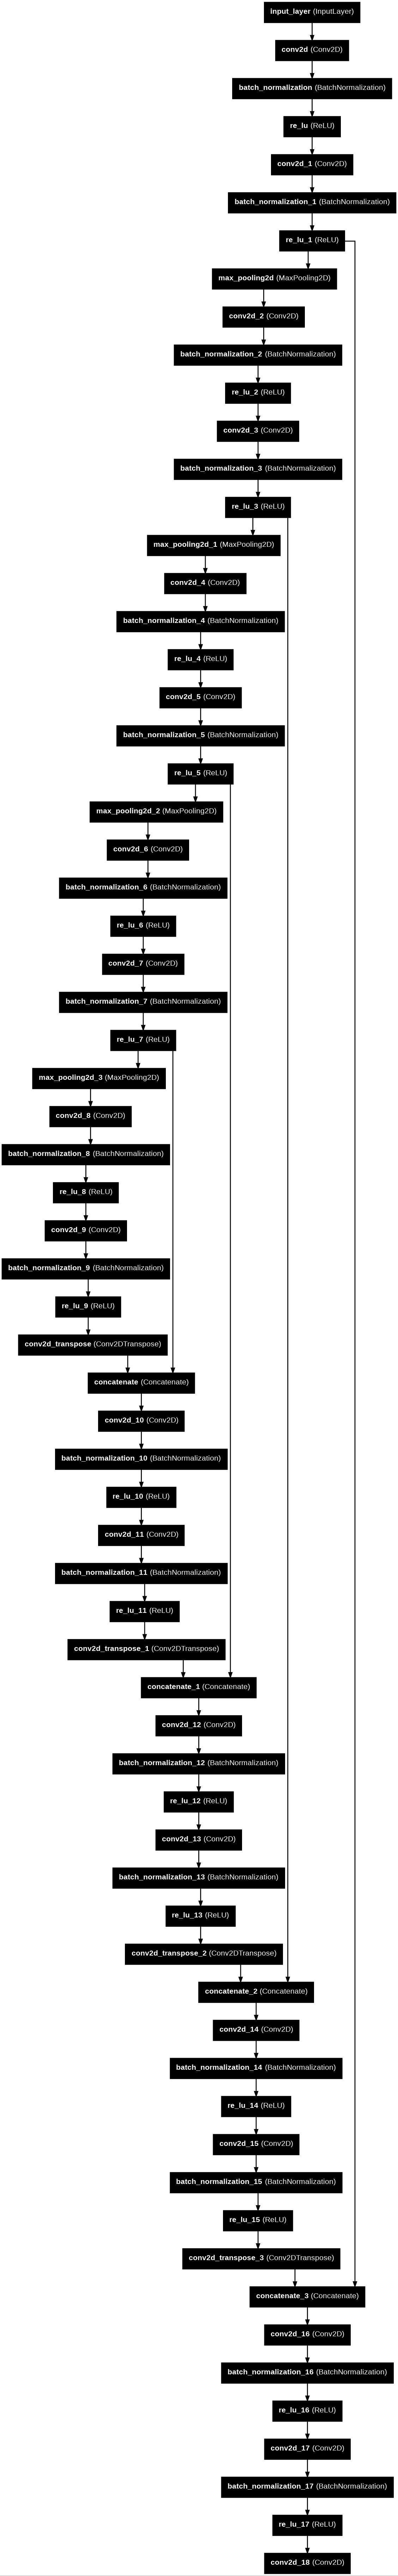

In [ ]:
tf.keras.utils.plot_model(model, "0_aug_230.jpg", show_shapes=False, show_dtype=False, show_layer_names=True, rankdir='TB', expand_nested=False, dpi=96)

In [ ]:
import cv2

img = cv2.imread('0_aug_230.jpg')

height = img.shape[0]
width = img.shape[1]
print(f"Size: {width}x{height} pixels")

resized = cv2.resize(img, (640, 640))
cv2.imwrite('/content/resized_image.jpg', resized)
height = resized.shape[0]
width = resized.shape[1]
print(f"Size: {width}x{height} pixels")

Size: 1128x7307 pixels
Size: 640x640 pixels


### Trying with my dataset

In [ ]:
import os

input_dir = "drive/MyDrive/IGVC/NET_U/oxford_pet_dataset/"
target_dir = "drive/MyDrive/ISRO/NET_U/oxford_pet_dataset_annotations/trimaps/"
img_size = (160, 160)
num_classes = 3
batch_size = 8

input_img_paths = sorted(
    [
        os.path.join(input_dir, fname)
        for fname in os.listdir(input_dir)
        if fname.endswith(".jpg")
    ]
)
target_img_paths = sorted(
    [
        os.path.join(target_dir, fname)
        for fname in os.listdir(target_dir)
        if fname.endswith(".png") and not fname.startswith(".")
    ]
)

print("Number of samples:", len(input_img_paths))

for input_path, target_path in zip(input_img_paths[:10], target_img_paths[:10]):
    print(input_path, "|", target_path)

Number of samples: 200
drive/MyDrive/ISRO/NET_U/oxford_pet_dataset/Abyssinian_167.jpg | drive/MyDrive/ISRO/NET_U/oxford_pet_dataset_annotations/trimaps/Abyssinian_167.png
drive/MyDrive/ISRO/NET_U/oxford_pet_dataset/Abyssinian_190.jpg | drive/MyDrive/ISRO/NET_U/oxford_pet_dataset_annotations/trimaps/Abyssinian_190.png
drive/MyDrive/ISRO/NET_U/oxford_pet_dataset/Abyssinian_63.jpg | drive/MyDrive/ISRO/NET_U/oxford_pet_dataset_annotations/trimaps/Abyssinian_63.png
drive/MyDrive/ISRO/NET_U/oxford_pet_dataset/Abyssinian_91.jpg | drive/MyDrive/ISRO/NET_U/oxford_pet_dataset_annotations/trimaps/Abyssinian_91.png
drive/MyDrive/ISRO/NET_U/oxford_pet_dataset/Bengal_10.jpg | drive/MyDrive/ISRO/NET_U/oxford_pet_dataset_annotations/trimaps/Bengal_10.png
drive/MyDrive/ISRO/NET_U/oxford_pet_dataset/Bengal_125.jpg | drive/MyDrive/ISRO/NET_U/oxford_pet_dataset_annotations/trimaps/Bengal_125.png
drive/MyDrive/ISRO/NET_U/oxford_pet_dataset/Bengal_198.jpg | drive/MyDrive/ISRO/NET_U/oxford_pet_dataset_annota

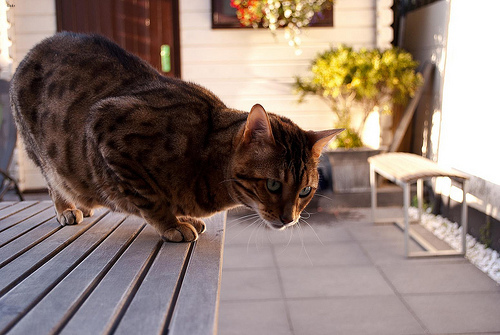

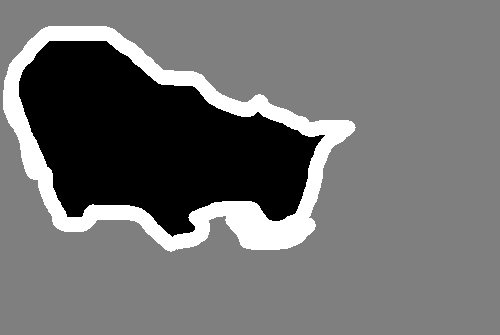

In [ ]:
from IPython.display import Image, display
from tensorflow.keras.preprocessing.image import load_img
import PIL
from PIL import ImageOps

# Display input image #7
display(Image(filename=input_img_paths[9]))

# Display auto-contrast version of corresponding target (per-pixel categories)
img = PIL.ImageOps.autocontrast(load_img(target_img_paths[9]))
display(img)

### Configure the data generator
In this particular code block, instead of using data generators to prepare the data, we will utilize the Sequence operation from the Keras deep learning framework. This method is much safer for multi-processing in comparison to using the generator because it only trains each sample once per epoch, which will avoid any unnecessary adjustments that we will need to make. We will then prepare the Sequence class in the utils module of Keras to compute, load, and vectorize batches of data. We will then construct the initialization function, an additional function to compute the length, and the final function that will generate batches of data.

In [ ]:
from tensorflow import keras
import numpy as np
from tensorflow.keras.preprocessing.image import load_img


class OxfordPets(keras.utils.Sequence):
    """Helper to iterate over the data (as Numpy arrays)."""

    def __init__(self, batch_size, img_size, input_img_paths, target_img_paths):
        self.batch_size = batch_size
        self.img_size = img_size
        self.input_img_paths = input_img_paths
        self.target_img_paths = target_img_paths

    def __len__(self):
        return len(self.target_img_paths) // self.batch_size

    def __getitem__(self, idx):
        """Returns tuple (input, target) correspond to batch #idx."""
        i = idx * self.batch_size
        batch_input_img_paths = self.input_img_paths[i : i + self.batch_size]
        batch_target_img_paths = self.target_img_paths[i : i + self.batch_size]
        x = np.zeros((self.batch_size,) + self.img_size + (3,), dtype="float32")
        for j, path in enumerate(batch_input_img_paths):
            img = load_img(path, target_size=self.img_size)
            x[j] = img
        y = np.zeros((self.batch_size,) + self.img_size + (1,), dtype="uint8")
        for j, path in enumerate(batch_target_img_paths):
            img = load_img(path, target_size=self.img_size, color_mode="grayscale")
            y[j] = np.expand_dims(img, 2)
            # Ground truth labels are 1, 2, 3. Subtract one to make them 0, 1, 2:
            y[j] -= 1
        return x, y

In [ ]:
import random

# Split our img paths into a training and a validation set
val_samples = 150
random.Random(1337).shuffle(input_img_paths)
random.Random(1337).shuffle(target_img_paths)
train_input_img_paths = input_img_paths[:-val_samples]
train_target_img_paths = target_img_paths[:-val_samples]
val_input_img_paths = input_img_paths[-val_samples:]
val_target_img_paths = target_img_paths[-val_samples:]

# Instantiate data Sequences for each split
train_gen = OxfordPets(
    batch_size, img_size, train_input_img_paths, train_target_img_paths
)
val_gen = OxfordPets(batch_size, img_size, val_input_img_paths, val_target_img_paths)

### Training the model

In [ ]:
model.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy")

callbacks = [
    keras.callbacks.ModelCheckpoint("drive/MyDrive/ISRO/NET_U/oxford_segmentation.h5", save_best_only=True)
]

# Train the model, doing validation at the end of each epoch.
epochs = 15
model.fit(train_gen, epochs=epochs, validation_data=val_gen, callbacks=callbacks)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: nan

6/6 ━━━━━━━━━━━━━━━━━━━━ 266s 43s/step - loss: nan - val_loss: nan
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 501ms/step - loss: nan - val_loss: nan
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 451ms/step - loss: nan - val_loss: nan
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 461ms/step - loss: nan - val_loss: nan
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 483ms/step - loss: nan - val_loss: nan
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 623ms/step - loss: nan - val_loss: nan
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 466ms/step - loss: nan - val_loss: nan
Epoch 8/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 473ms/step - loss: nan - val_loss: nan
Epoch 9/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 486ms/step - loss: nan - val_loss: nan
Epoch 10/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 504ms/step - loss: nan - val_loss: nan
Epoch 11/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 702ms/step - loss: nan - val_loss: nan
Epoch 12/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 474ms/step - loss: nan - val_loss: nan
Epoch 13/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 485ms/step - loss: nan - val_los

### Results

18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step


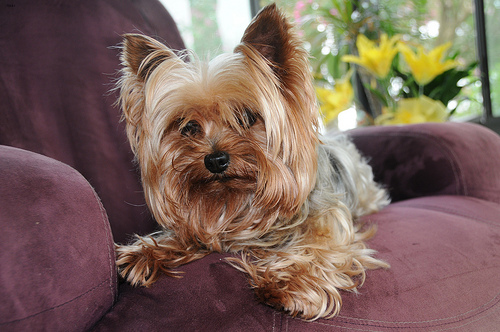

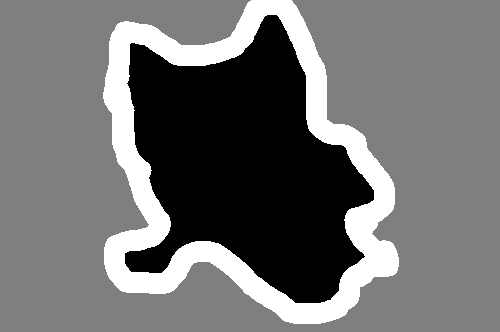

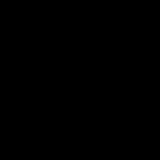

In [ ]:
# Generate predictions for all images in the validation set

val_gen = OxfordPets(batch_size, img_size, val_input_img_paths, val_target_img_paths)
val_preds = model.predict(val_gen)


def display_mask(i):
    """Quick utility to display a model's prediction."""
    mask = np.argmax(val_preds[i], axis=-1)
    mask = np.expand_dims(mask, axis=-1)
    img = PIL.ImageOps.autocontrast(keras.preprocessing.image.array_to_img(mask))
    display(img)


# Display results for validation image #10
i = 10

# Display input image
display(Image(filename=val_input_img_paths[i]))

# Display ground-truth target mask
img = PIL.ImageOps.autocontrast(load_img(val_target_img_paths[i]))
display(img)

# Display mask predicted by our model
display_mask(i)  # Note that the model only sees inputs at 150x150.